In [46]:
import os
import random
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.transforms import Bbox
import networkx as nx
import seaborn as sns
import pandas as pd

# Add project source to path
sys.path.append(
    os.path.join(
        '..',  # notes -> root
    )
)

from src.simulation import (
    build_graph,
    build_kernel_bank,
    assign_kernels,
    build_initial_state,
    heterogeneous_contagion_process,
    get_activations,
    load_kernel,
    simple_kernel
)
from src.inference.inference import (
    fit_stan,
    get_posterior_draws,
)

import fig_settings as fs

fs.set_colors()
fs.set_fonts()

In [47]:
RESULTS_DIR = Path('../results/cv/cv_basic')
df = pd.read_parquet(RESULTS_DIR / "_cv_curve.parquet")

In [48]:
twoSimple_K1_fpath = "fig3_twoSimpleOmega0.1_K1_mu_draws.npy"
twoSimple_K2_fpath = "fig3_twoSimpleOmega0.1_K2_mu_draws.npy"
twoSimple_hero_rep = 0

# skip re-running inference if posterior draws saved
if not (os.path.isfile(twoSimple_K1_fpath) and os.path.isfile(twoSimple_K2_fpath)):
    # seeded with rep to match original CV data
    GRAPH_CFG = {'type': 'sbm', 'params': {'n': 256, 'avg_degree': 18, 'epsilon': 0.9}}
    A, kmax = build_graph(GRAPH_CFG, seed=twoSimple_hero_rep)
    n = A.shape[0]

    KERNELS_CFG = [{'type': 'simple', 'beta': 0.01},
                   {'type': 'simple', 'beta': 0.04}]
    bank = build_kernel_bank(KERNELS_CFG, kmax)
    ASSIGN_CFG = {'mode': 'block_flip', 'omega': 0.1}
    labels = assign_kernels(n, ASSIGN_CFG, n_kernels = len(KERNELS_CFG), seed=twoSimple_hero_rep)

    c = np.stack([bank[labels[l]] for l in range(n)])
    x0 = build_initial_state(n, 0.25, seed=twoSimple_hero_rep)
    x = heterogeneous_contagion_process(A, 0.1, c, x0, tmax=1000, random_seed=twoSimple_hero_rep)
    M, N = get_activations(x.T, A, kmax)

    SAMPLING_CFG = {"iter_sampling":300,"iter_warmup":900,"chains":1,"adapt_delta":0.95}
    configf = '../config/models/nonparametric_eb.yaml'
    
    if not os.path.isfile(twoSimple_K1_fpath):
        K1_res = fit_stan(M, N, configf, instance_params={"K": 1, "stan_file": '../src/models/mixture_nonparametric_eb.stan', "sampling": {**SAMPLING_CFG}})
        K1_mu_draws = get_posterior_draws(K1_res, "mu")
        np.save("fig3_twoSimpleOmega0.1_K1_mu_draws", K1_mu_draws)

    if not os.path.isfile(twoSimple_K2_fpath):
        K2_res = fit_stan(M, N, configf, instance_params={"K": 2, "stan_file": '../src/models/mixture_nonparametric_eb.stan', "sampling": {**SAMPLING_CFG}})
        K2_mu_draws = get_posterior_draws(K2_res, "mu")
        np.save("fig3_twoSimpleOmega0.1_K2_mu_draws", K2_mu_draws)

twoSimple_K1_mu_draws = np.load(twoSimple_K1_fpath); twoSimple_K1_mu_draws = twoSimple_K1_mu_draws[:, 0, :]
twoSimple_K2_mu_draws = np.load(twoSimple_K2_fpath)

In [49]:
oneComplex_K1_fpath = "fig3_oneComplex_K1_mu_draws.npy"
oneComplex_K2_fpath = "fig3_oneComplex_K2_mu_draws.npy"
oneComplex_hero_rep = 0

# skip re-running inference if posterior draws saved
if not (os.path.isfile(oneComplex_K1_fpath) and os.path.isfile(oneComplex_K2_fpath)):
    GRAPH_CFG = {'type': 'sbm', 'params': {'n': 256, 'avg_degree': 18, 'epsilon': 0.9}}
    A, kmax = build_graph(GRAPH_CFG, seed=oneComplex_hero_rep)
    n = A.shape[0]

    NP_KERNEL = load_kernel('../data/np_complex_kernel.txt', kmax)
    c = np.tile(NP_KERNEL, (n, 1))
    x0 = build_initial_state(n, 0.25, seed=oneComplex_hero_rep)
    x = heterogeneous_contagion_process(A, 0.1, c, x0, tmax=1000, random_seed=oneComplex_hero_rep)
    M, N = get_activations(x.T, A, kmax)

    SAMPLING_CFG = {"iter_sampling":300,"iter_warmup":900,"chains":1,"adapt_delta":0.95}
    configf = '../config/models/nonparametric_eb.yaml'
    
    if not os.path.isfile(oneComplex_K1_fpath):
        K1_res = fit_stan(M, N, configf, instance_params={"K": 1, "stan_file": '../src/models/mixture_nonparametric_eb.stan', "sampling": {**SAMPLING_CFG}})
        K1_mu_draws = get_posterior_draws(K1_res, "mu")
        np.save("fig3_oneComplex_K1_mu_draws", K1_mu_draws)

    if not os.path.isfile(oneComplex_K2_fpath):
        K2_res = fit_stan(M, N, configf, instance_params={"K": 2, "stan_file": '../src/models/mixture_nonparametric_eb.stan', "sampling": {**SAMPLING_CFG}})
        K2_mu_draws = get_posterior_draws(K2_res, "mu")
        np.save("fig3_oneComplex_K2_mu_draws", K2_mu_draws)
        
oneComplex_K1_mu_draws = np.load(oneComplex_K1_fpath); oneComplex_K1_mu_draws = oneComplex_K1_mu_draws[:, 0, :]
oneComplex_K2_mu_draws = np.load(oneComplex_K2_fpath)

In [ ]:
def rep_curves(df: pd.DataFrame, case: str) -> dict[int, pd.DataFrame]:
    """Extraction: one sorted (K, mean_lppd, se_lppd) frame per rep, for one case."""
    sub = df[df["dgp_label"] == case]
    return {int(rep): g.sort_values("K") for rep, g in sub.groupby("rep")}


def select_K_1se(curve: pd.DataFrame) -> int:
    """Most parsimonious K within 1 SE of the best K (higher lppd is better)."""
    c = curve.sort_values("K")
    best = c.loc[c["mean_lppd"].idxmax()]
    se = best["se_lppd"]
    if not np.isfinite(se):
        return int(best["K"])
    threshold = best["mean_lppd"] - se
    return int(c.loc[c["mean_lppd"] >= threshold, "K"].min())

def plot_curves(ax, df: pd.DataFrame, case: str, hero_rep: int, hero_color, leg_loc):
    curves = rep_curves(df, case)
    hero = curves[hero_rep]
    
    Ks = hero["K"].to_numpy()
    mean = hero["mean_lppd"].to_numpy()
    se = hero["se_lppd"].to_numpy()
    
    # 1-SE construction for hero rep
    imax = int(np.argmax(mean))
    threshold = mean[imax] - se[imax]
    sel_K = select_K_1se(hero)
    sel_mean = float(hero.loc[hero["K"] == sel_K, "mean_lppd"].iloc[0])

    # other reps in background
    for r, g in curves.items():
        if r == hero_rep:
            continue
        ax.plot(g["K"], g["mean_lppd"], color='darkgrey', lw=1.5, alpha=0.25, zorder=1)
        
    # hero rep: line + per-node SE band
    ax.fill_between(Ks, mean - se, mean + se, color=hero_color, alpha=0.3, zorder=2,
                    label="$\\pm 1$ SE")
    ax.plot(Ks, mean, color=hero_color, lw=2.0, marker="o", ms=6, zorder=4)

    # 1-SE threshold, selected K
    ax.axhline(threshold, color='grey', ls='-.', lw=1.3, zorder=3,
               label="1-SE threshold")
    ax.scatter([sel_K+0.015], [sel_mean], s=120, facecolors="none", edgecolors='black', lw=1.5, zorder=5)

    ax.set_xticks(sorted(df["K"].unique()))
    ax.set_xlabel("Num. mixture components, $K$")
    ax.set_ylabel("Mean LPPD / node")
    
    band = mpatches.Patch(color=hero_color, alpha=0.3)
    line = mlines.Line2D([0], [0], color=hero_color, marker="o", lw=2.0)
    thresh = mlines.Line2D([0], [0], color='grey', ls='-.', lw=1.3)
    ax.legend(
        handles = [(band, line), thresh],
        labels = ["mean $\\pm 1$ SE", "1-SE rule"],
        handlelength=1.5, handleheight=1.5,
        fancybox=False,
        loc=leg_loc,
        borderaxespad=0.2
    )
    # ax.legend(fancybox=False, loc='lower right')
    
def _hpdi(x, prob=0.5):
    """Narrowest interval containing `prob` of 1D samples."""
    x = np.sort(x)
    n = len(x)
    k = int(np.floor(prob * n))      # number of points inside the interval
    widths = x[k:] - x[:n - k]       # width of every candidate window
    i = np.argmin(widths)            # pick the narrowest
    return x[i], x[i + k]

def hpdi_bounds(X, prob=0.5):
    lower, upper = np.empty(X.shape[1]), np.empty(X.shape[1])
    for j in range(X.shape[1]):
        lower[j], upper[j] = _hpdi(X[:, j], prob=prob)
    return lower, upper
        

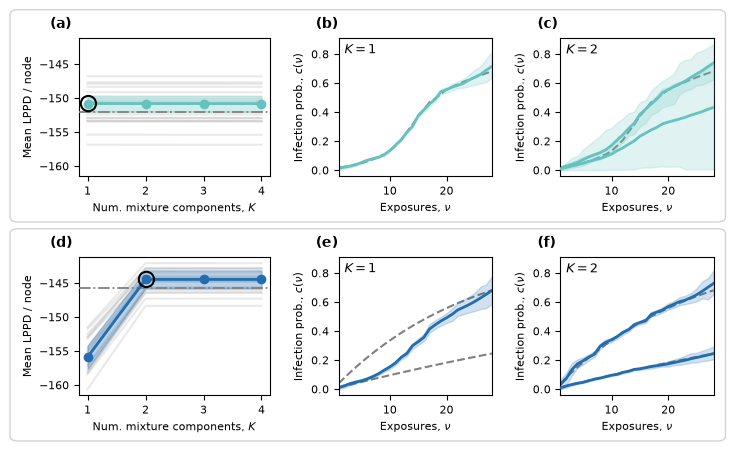

In [51]:
fig, axs = plt.subplots(
    2, 3,
    figsize=(7.0, 4.25),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1.25, 1, 1], "wspace": 0.1, "hspace": 0.1},
)
kmax = 28
nus = range(1, kmax + 1)
# PANEL A - lppd curves for one complex gt
plot_curves(axs[0,0], df, 'oneComplex', oneComplex_hero_rep, fs.palette[2], 'upper right')
# axs[0,0].annotate('1-SE pick', (1.1, -149), xycoords='data', fontsize=9)

# PANEL B - one complex gt, K = 1
gt_kernel = load_kernel('../data/np_complex_kernel.txt', kmax)
axs[0,1].plot(nus, gt_kernel, color='grey', zorder=1, ls='--')
axs[0,1].plot(nus, np.mean(oneComplex_K1_mu_draws, axis=0)[:kmax], lw=2.0, color=fs.palette[2], zorder=2)
lower, upper = hpdi_bounds(oneComplex_K1_mu_draws, prob=0.9)
axs[0,1].fill_between(nus, lower[:kmax], upper[:kmax], color=fs.palette[2], alpha=0.2, zorder=2)
axs[0,1].annotate('$K=1$', (2, 0.8), xycoords='data', fontsize=9)

# PANEL C - one complex gt, K = 2
axs[0,2].plot(nus, gt_kernel, color='grey', zorder=1, ls='--')
axs[0,2].plot(nus, np.mean(oneComplex_K2_mu_draws[:, 0, :], axis=0)[:kmax], lw=2.0, color=fs.palette[2], zorder=3)
lower, upper = hpdi_bounds(oneComplex_K2_mu_draws[:, 0, :], prob=0.9)
axs[0,2].fill_between(nus, lower[:kmax], upper[:kmax], color=fs.palette[2], alpha=0.2, zorder=3)

axs[0,2].plot(nus, np.mean(oneComplex_K2_mu_draws[:, 1, :], axis=0)[:kmax], lw=2.0, color=fs.palette[2], zorder=2)
lower, upper = hpdi_bounds(oneComplex_K2_mu_draws[:, 1, :], prob=0.9)
axs[0,2].fill_between(nus, lower[:kmax], upper[:kmax], color=fs.palette[2], alpha=0.2, zorder=2)

axs[0,2].sharey(axs[0,1])
axs[1,1].sharey(axs[0,1])
axs[1,2].sharey(axs[0,1])

axs[0,2].annotate('$K=2$', (2, 0.8), xycoords='data', fontsize=9)

# PANEL D - lppd curves for two simple gt
plot_curves(axs[1,0], df, 'twoSimpleOmega0.1', twoSimple_hero_rep, fs.palette[4], 'lower right')
axs[0,0].sharey(axs[1,0])
# axs[1,0].annotate('1-SE pick', (0.9, -143), xycoords='data', fontsize=9)

# PANEL E - two simple gt, K = 1
gt_kernel1 = simple_kernel(0.01, kmax)
gt_kernel2 = simple_kernel(0.04, kmax)
axs[1,1].plot(nus, gt_kernel1, color='grey', zorder=1, ls='--')
axs[1,1].plot(nus, gt_kernel2, color='grey', zorder=1, ls='--')
axs[1,1].plot(nus, np.mean(twoSimple_K1_mu_draws, axis=0)[:kmax], lw=2.0, color=fs.palette[4], zorder=2)
lower, upper = hpdi_bounds(twoSimple_K1_mu_draws, prob=0.9)
axs[1,1].fill_between(nus, lower[:kmax], upper[:kmax], color=fs.palette[4], alpha=0.2, zorder=2)
axs[1,1].annotate('$K=1$', (2, 0.8), xycoords='data', fontsize=9)

# PANEL F - two simple gt, K = 2
axs[1,2].plot(nus, gt_kernel1, color='grey', zorder=1, ls='--')
axs[1,2].plot(nus, gt_kernel2, color='grey', zorder=1, ls='--')
axs[1,2].plot(nus, np.mean(twoSimple_K2_mu_draws[:, 0, :], axis=0)[:kmax], lw=2.0, color=fs.palette[4], zorder=3)
lower, upper = hpdi_bounds(twoSimple_K2_mu_draws[:, 0, :], prob=0.9)
axs[1,2].fill_between(nus, lower[:kmax], upper[:kmax], color=fs.palette[4], alpha=0.2, zorder=3)

axs[1,2].plot(nus, np.mean(twoSimple_K2_mu_draws[:, 1, :], axis=0)[:kmax], lw=2.0, color=fs.palette[4], zorder=2)
lower, upper = hpdi_bounds(twoSimple_K2_mu_draws[:, 1, :], prob=0.9)
axs[1,2].fill_between(nus, lower[:kmax], upper[:kmax], color=fs.palette[4], alpha=0.2, zorder=2)

axs[1,2].annotate('$K=2$', (2, 0.8), xycoords='data', fontsize=9)

for ax in [axs[0,1], axs[0,2], axs[1,1], axs[1,2]]:
    ax.set_xlim(1, kmax)
    ax.set_xlabel("Exposures, $\\nu$")
    ax.set_ylabel("Infection prob., $c(\\nu)$")

axs[0,0].text(-0.15, 1.1, "(a)", transform=axs[0,0].transAxes, fontweight='bold', va='center', ha='left')
axs[0,1].text(-0.15, 1.1, "(b)", transform=axs[0,1].transAxes, fontweight='bold', va='center', ha='left')
axs[0,2].text(-0.15, 1.1, "(c)", transform=axs[0,2].transAxes, fontweight='bold', va='center', ha='left')
axs[1,0].text(-0.15, 1.1, "(d)", transform=axs[1,0].transAxes, fontweight='bold', va='center', ha='left')
axs[1,1].text(-0.15, 1.1, "(e)", transform=axs[1,1].transAxes, fontweight='bold', va='center', ha='left')
axs[1,2].text(-0.15, 1.1, "(f)", transform=axs[1,2].transAxes, fontweight='bold', va='center', ha='left')

fig.canvas.draw()
fig.set_layout_engine('none')
renderer = fig.canvas.get_renderer()

def _row_fig_bbox(row_axes):
    """Union of a row's tight bboxes (incl. labels), in figure-fraction coords."""
    bb = Bbox.union([ax.get_tightbbox(renderer) for ax in row_axes])
    return bb.transformed(fig.transFigure.inverted())

_pad = 0.017
for _row in (axs[0, :], axs[1, :]):
    _bb = _row_fig_bbox(_row)
    fig.add_artist(mpatches.FancyBboxPatch(
        (_bb.x0 - _pad, _bb.y0 - _pad),
        _bb.width + 2 * _pad, _bb.height + 2 * _pad,
        boxstyle="round,pad=0,rounding_size=0.012",
        linewidth=1.0, edgecolor="lightgrey", facecolor="none",
        transform=fig.transFigure, zorder=-1, clip_on=False,
    ))
    
plt.savefig('../figs/fig4.svg', bbox_inches='tight')
plt.savefig('../figs/fig4.pdf', bbox_inches='tight')
plt.show()

In [66]:
def plot_minimal_curves(ax, df: pd.DataFrame, case: str, hero_rep: int, hero_color):
    curves = rep_curves(df, case)
    hero = curves[hero_rep]
    
    Ks = hero["K"].to_numpy()
    mean = hero["mean_lppd"].to_numpy()
    se = hero["se_lppd"].to_numpy()
    
    # 1-SE construction for hero rep
    imax = int(np.argmax(mean))
    threshold = mean[imax] - se[imax]
    sel_K = select_K_1se(hero)
    sel_mean = float(hero.loc[hero["K"] == sel_K, "mean_lppd"].iloc[0])
        
    # hero rep: line + per-node SE band
    ax.fill_between(Ks, mean - se, mean + se, color=hero_color, alpha=0.3, zorder=2,
                    label="$\\pm 1$ SE")
    ax.plot(Ks, mean, color=hero_color, lw=2.0, marker="o", ms=6, zorder=4)
    
    # to circle
    return sel_K, sel_mean
    

def plot_mu_with_shading(ax, mu_array, kmax, color, zorder):
    ax.plot(range(1,kmax+1), np.mean(mu_array, axis=0)[:kmax], color=color, zorder=zorder)
    lower, upper = hpdi_bounds(mu_array, prob=0.9)
    ax.fill_between(range(1,kmax+1), lower[:kmax], upper[:kmax], color=color, alpha=0.2, zorder=zorder)

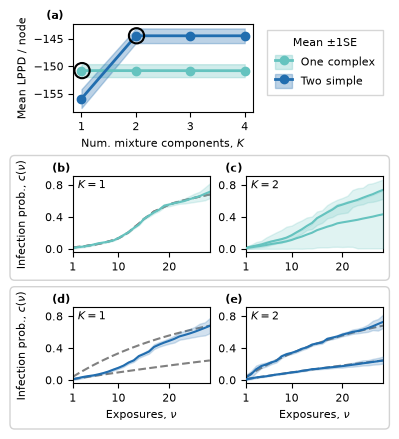

In [105]:
fig = plt.figure(figsize=(3.75, 4.2), constrained_layout=True)
top, bot = fig.subfigures(2,1, height_ratios=[1,1.8])
kmax = 28
nus = range(1, kmax + 1)

# top row: lppd curves
ax_t = top.subplots(1,1)
sel_K, sel_mean = plot_minimal_curves(ax_t, df, 'oneComplex', oneComplex_hero_rep, fs.palette[2])
ax_t.scatter([sel_K+0.011], [sel_mean], s=120, facecolors="none", edgecolors='black', lw=1.5, zorder=5)

sel_K, sel_mean = plot_minimal_curves(ax_t, df, 'twoSimpleOmega0.1', twoSimple_hero_rep, fs.palette[4])
ax_t.scatter([sel_K+0.011], [sel_mean], s=120, facecolors="none", edgecolors='black', lw=1.5, zorder=5)

ax_t.set_xticks([1,2,3,4])
ax_t.set_xlabel("Num. mixture components, $K$")
ax_t.set_ylabel("Mean LPPD / node")

band1 = mpatches.Patch(color=fs.palette[2], alpha=0.3)
line1 = mlines.Line2D([0], [0], color=fs.palette[2], marker="o", lw=2.0)
band2 = mpatches.Patch(color=fs.palette[4], alpha=0.3)
line2 = mlines.Line2D([0], [0], color=fs.palette[4], marker="o", lw=2.0)
ax_t.legend(
    handles = [(band1, line1), (band2, line2)],
    labels = ["One complex", "Two simple"],
    handlelength=1.5, handleheight=1.5,
    fancybox=False,
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    title="Mean $\\pm 1$SE",
    title_fontsize=8,
    borderpad=0.7
)

# bottom section: kernels
ax_b = bot.subplots(2, 2, gridspec_kw={"hspace": 0.1})
gt_kernel = load_kernel('../data/np_complex_kernel.txt', kmax)
ax_b[0,0].plot(nus, gt_kernel, color='grey', zorder=1, ls='--')
ax_b[0,0].plot(nus, gt_kernel, color='grey', zorder=1, ls='--')

plot_mu_with_shading(ax_b[0,0], oneComplex_K1_mu_draws, kmax, fs.palette[2], 2)
ax_b[0,0].annotate('$K=1$', (2, 0.75), xycoords='data', fontsize=8)

plot_mu_with_shading(ax_b[0,1], oneComplex_K2_mu_draws[:, 0, :], kmax, fs.palette[2], 3)
plot_mu_with_shading(ax_b[0,1], oneComplex_K2_mu_draws[:, 1, :], kmax, fs.palette[2], 2)
ax_b[0,1].annotate('$K=2$', (2, 0.75), xycoords='data', fontsize=8)

# second col: two simple gt
ax_b[1,0].plot(nus, simple_kernel(0.01, kmax), color='grey', zorder=1, ls='--')
ax_b[1,0].plot(nus, simple_kernel(0.04, kmax), color='grey', zorder=1, ls='--')
ax_b[1,1].plot(nus, simple_kernel(0.01, kmax), color='grey', zorder=1, ls='--')
ax_b[1,1].plot(nus, simple_kernel(0.04, kmax), color='grey', zorder=1, ls='--')

plot_mu_with_shading(ax_b[1,0], twoSimple_K1_mu_draws, kmax, fs.palette[4], 2)
ax_b[1,0].annotate('$K=1$', (2, 0.75), xycoords='data', fontsize=8)

plot_mu_with_shading(ax_b[1,1], twoSimple_K2_mu_draws[:, 0, :], kmax, fs.palette[4], 3)
plot_mu_with_shading(ax_b[1,1], twoSimple_K2_mu_draws[:, 1, :], kmax, fs.palette[4], 2)
ax_b[1,1].annotate('$K=2$', (2, 0.75), xycoords='data', fontsize=8)

ax_b[0,0].sharey(ax_b[0,1])
ax_b[1,0].sharey(ax_b[0,1])
ax_b[1,1].sharey(ax_b[0,1])

for ax in ax_b.flatten():
    ax.set_xlim(1, kmax)
    ax.set_xticks([1, 10, 20])
    ax.set_yticks([0.0, 0.4, 0.8])
for ax in [ax_b[0,0], ax_b[1,0]]:
    ax.set_ylabel("Infection prob., $c(\\nu)$", labelpad=12)
for ax  in [ax_b[1,0], ax_b[1,1]]:
    ax.set_xlabel("Exposures, $\\nu$")

ax_t.text(-0.15, 1.1, "(a)", transform=ax_t.transAxes, fontsize=8, fontweight='bold', va='center', ha='left')
ax_b[0,0].text(-0.15, 1.1, "(b)", transform=ax_b[0,0].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')
ax_b[0,1].text(-0.15, 1.1, "(c)", transform=ax_b[0,1].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')
ax_b[1,0].text(-0.15, 1.1, "(d)", transform=ax_b[1,0].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')
ax_b[1,1].text(-0.15, 1.1, "(e)", transform=ax_b[1,1].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')

fig.canvas.draw()
fig.set_layout_engine('none')
renderer = fig.canvas.get_renderer()

def _row_fig_bbox(row_axes):
    """Union of a row's tight bboxes (incl. labels), in figure-fraction coords."""
    bb = Bbox.union([ax.get_tightbbox(renderer) for ax in row_axes])
    return bb.transformed(fig.transFigure.inverted())

_pad = 0.017
for _row in (ax_b[0, :], ax_b[1, :]):
    _bb = _row_fig_bbox(_row)
    fig.add_artist(mpatches.FancyBboxPatch(
        (_bb.x0 - _pad, _bb.y0 - _pad),
        _bb.width + 2 * _pad, _bb.height + 2 * _pad,
        boxstyle="round,pad=0,rounding_size=0.012",
        linewidth=1.0, edgecolor="lightgrey", facecolor="none",
        transform=fig.transFigure, zorder=-1, clip_on=False,
    ))
    
plt.savefig('../figs/fig3.svg', bbox_inches='tight')
plt.savefig('../figs/fig3.pdf', bbox_inches='tight')
plt.show()